# **README**

# Multi-Class Classification - Machine Failure Prediction (AI4I 2020)
Predicting industrial equipment failures using **XGBoost**, **LightGBM** and **RandomForest Classifier** on a highly imbalanced dataset.

## Problem
3.4% of machines in the AI4I 2020 dataset experience failure —
a severe class imbalance that makes standard accuracy misleading.
The goal is to identify failures early to minimize downtime and cost.

## Dataset
- **Source**: AI4I 2020 Predictive Maintenance Dataset ([UCI ML Repository](https://www.google.com/url?q=https%3A%2F%2Farchive.ics.uci.edu%2Fdataset%2F601%2Fai4i%2B2020%2Bpredictive%2Bmaintenance%2Bdataset))
- **Size**: 10,000 rows, 14 features
- **Target**: Multi-class — Machine Failure by which process failure modes (TWF, HDF, PWF, OSF, RNF)
- **Class imbalance**: ~3.4% positive class

## Approach
- Hyperparameter tuning with GridSearchCV (scoring = `f1_macro`)
- Evaluated using PR-AUC over ROC-AUC due to class imbalance
- Threshold tuned to meet a business recall target of ≥ 0.70 (catch at least 70% of real failures)

## Results

### Model Comparison (Default Threshold)
| Model                  | Precision | Recall | PR-AUC |
|------------------------|-----------|--------|--------|
| XGBoost                | 0.947     | 0.714  | 0.646  |
| LightGBM               | 0.961     | 0.700  | 0.647  |
| RandomForestClassifier | 0.459     | 0.714  | 0.537  |

### Threshold-Adjusted Results (Business Target: Recall ≥ 0.70)
Thresholds were tuned on the binary failure signal (any failure vs. no failure) to maximise precision while guaranteeing recall ≥ 0.70.

| Model                  | Threshold | Precision | Recall |
|------------------------|-----------|-----------|--------|
| XGBoost                | 0.435     | 0.943     | 0.714  |
| LightGBM               | 0.572     | 0.961     | 0.700  |
| RandomForestClassifier | 0.703     | 0.459     | 0.714  |

> **Best model: XGBoost** — at a threshold of 0.430, it correctly identifies **71% of actual failures** while maintaining **94% precision**, making it the most reliable choice for production deployment.

---





In [1]:
import numpy as np
import pandas as pd
from IPython.display import display,Markdown

from pathlib import Path
import sys

sys.path.append(str(Path.cwd().parent))

from src.models.train import load_data, analysis_multi_target, identify_columns, encode_multiclass_target,split_data, save_splitted_test_data, get_multiclass_model ,save_selected_models, save_predicted_prob_value, get_multiclass_model_score
from src.models.predict import run_multiclass_prediction,get_feature_importance 
from src.visualization.visualize import plot_count, plot_heatmap,plot_multi_box, plot_bar_with_thredshold, plot_score_comparison_chart

sys.path.append('..')

%load_ext autoreload
%autoreload 2

import warnings
warnings.filterwarnings("ignore", category=UserWarning)



# 1. Load Preprocessed Data

In [2]:
df = load_data()
df.head(3)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0


# 2. Univariate Analysis - Target Variable

Since this notebook's goal is to predict whether a machine will fail due to process-related issues—specifically one of the five failure modes (TWF, HDF, PWF, OSF, and RNF)—these five variables will serve as the target variables.

Therefore, this is a multi-class classification task aimed at identifying which type of failure is likely to occur based on the independent variables related to machine operation and process conditions.

In [3]:
target = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF']
for col in target:
  print(f'Unique value of target variable {col}: {df[col].unique()}')

Unique value of target variable TWF: [0 1]
Unique value of target variable HDF: [0 1]
Unique value of target variable PWF: [0 1]
Unique value of target variable OSF: [0 1]
Unique value of target variable RNF: [0 1]


After target variable is determined, I have investigated target problem type to confirm the machine problem type.

Depending on the type of machine learning problem, I decided to examine the target variable's distribution to determine whether class imbalance exists.

The target variable was analyzed by examining class counts, proportions, and visualizing the distribution using a count plot. The results indicate a moderately imbalanced dataset, which informed the choice of evaluation metrics and modeling approach.

In [4]:
df_class_ratio = analysis_multi_target(df = df, multi_target= target)
df_class_ratio

Machine Learning/Target Problem Type: classification
Target Class TWF Distribution Ratio: 1.0. Class Imbalance Detected.
Target Class HDF Distribution Ratio: 0.99. Class Imbalance Detected.
Target Class PWF Distribution Ratio: 0.99. Class Imbalance Detected.
Target Class OSF Distribution Ratio: 0.99. Class Imbalance Detected.
Target Class RNF Distribution Ratio: 1.0. Class Imbalance Detected.
Recommended Model: 
- XGBoost or LightGBM with class weights or SMOTE
- RandomForestClassifier with `class_weight='balanced'`


,variable,class_ratio
0,TWF,0.9954
1,HDF,0.9885
2,PWF,0.9905
3,OSF,0.9902
4,RNF,0.9981


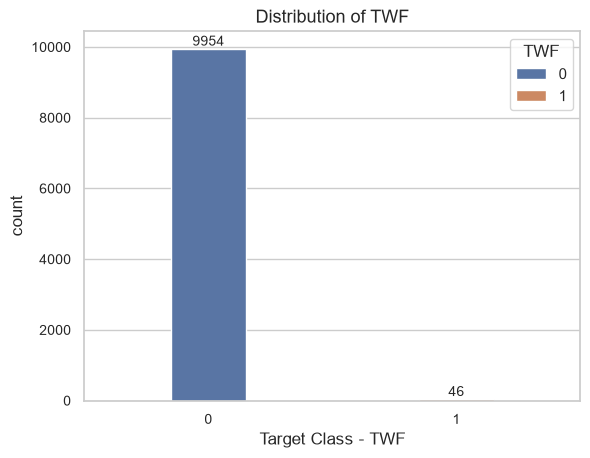

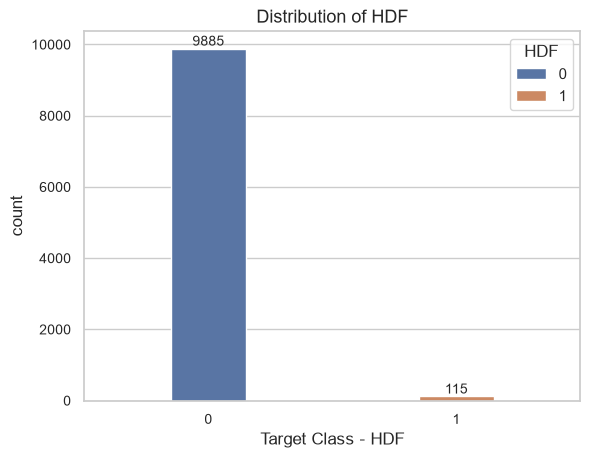

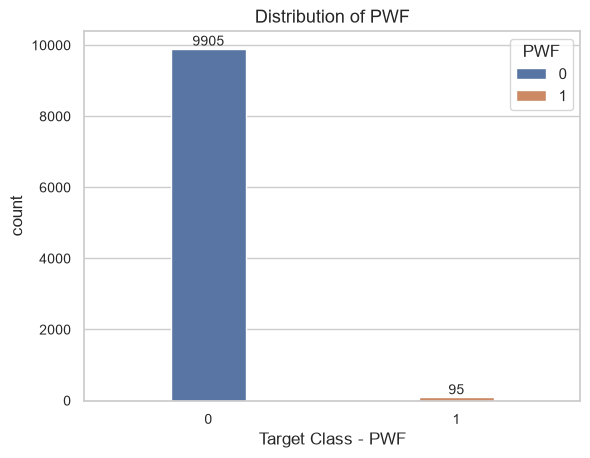

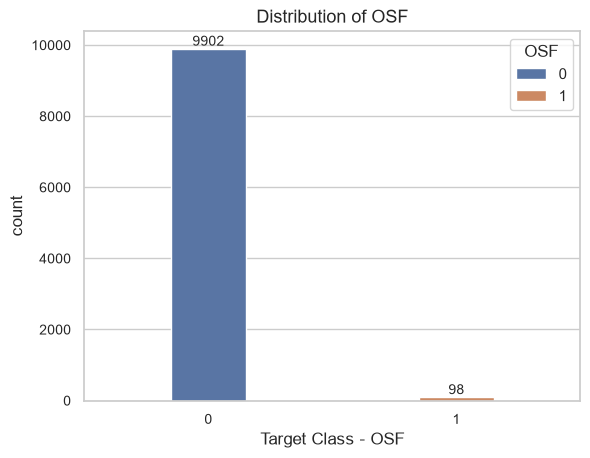

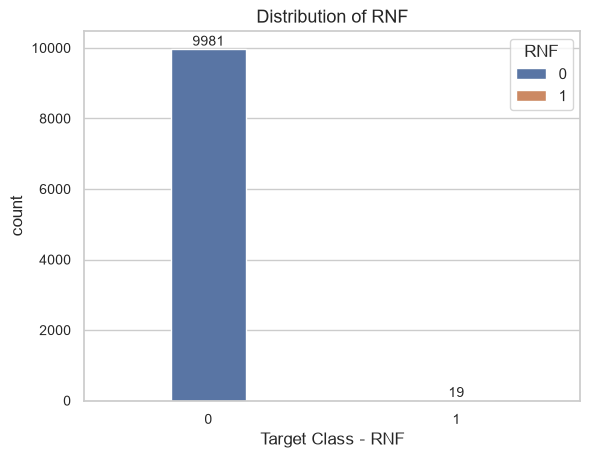

In [5]:
# plot target distribution
for t in target:
    plot_count(df= df, target= t, xlabel=f"Target Class - {t}",title=f"Distribution of {t}")

# 3. Correlation Analysis
## 3.1 Identify column data type
First, we drop 'UDI' and 'Product ID' column as it is just an unit identifier for each record and it could not give us useful information in exploratory analysis and classification.

Numerical and categorical features are listed to make the exploratory analysis easier and more organized.

In [6]:
# unit identifier columns
identifier_cols = ['UDI','Product ID']
# failure indicator 
failure_indicator = ['TWF', 'HDF', 'PWF', 'OSF', 'RNF'] 

cat_cols, num_cols = identify_columns(target= 'Machine failure', df= df, id_cols= identifier_cols, fmode_cols= failure_indicator)

Categorical Columns: ['Type']
Numerical Columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


## 3.2 Numerical variables Vs Target

To implement multi-class classification in this phase, the relationship between features and target - five process failure modes is required to be investigated.

According to heatmap below, the variables Air temperature and Torque show a moderate linear relationship with the target variable HDF.

Only the Tool wear variable exhibits a slight linear relationship with the target variable TWF.

The variables Torque and Tool wear are moderately linearly related to the target variable OSF.

In contrast, no features demonstrate a strong positive or negative linear relationship with the target variables RNF and PWF.

Overall, the correlation analysis indicates that only a few numerical features have moderate relationships with specific failure modes, while most variables exhibit weak linear correlations with the target variables. 
This suggests that machine failure patterns may depend on complex or non-linear interactions among features rather than strong direct linear relationships alone.

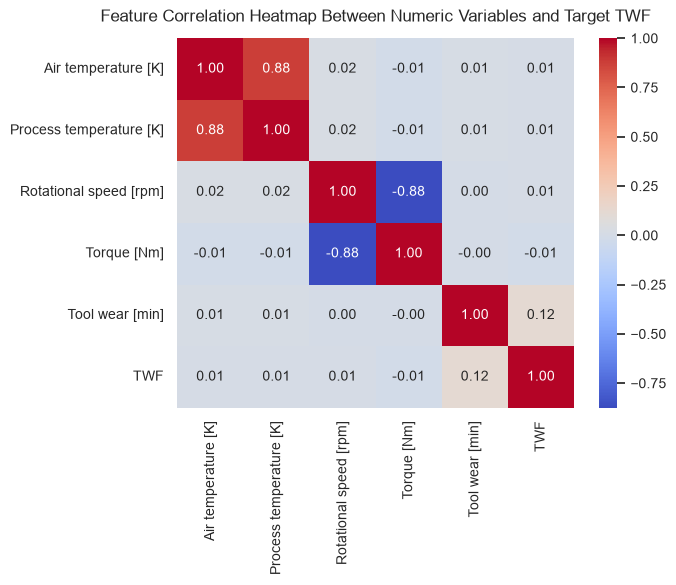

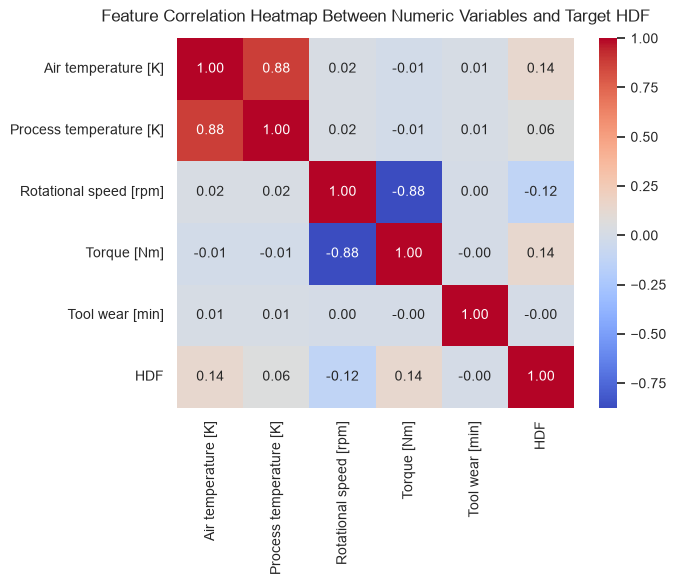

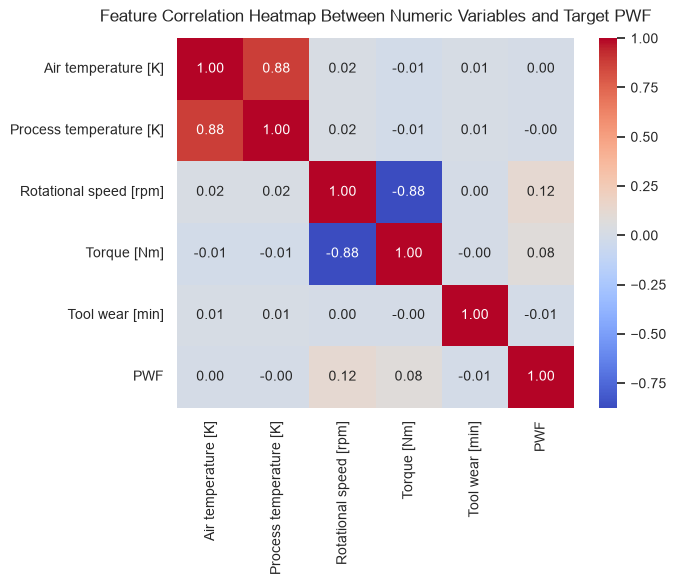

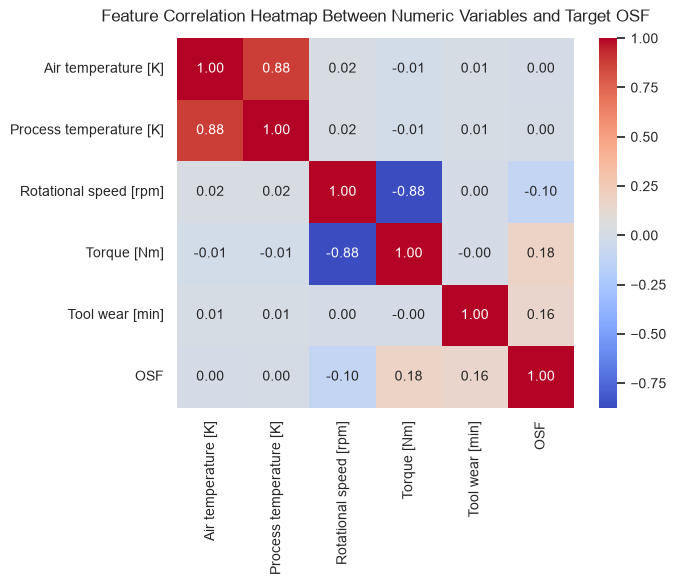

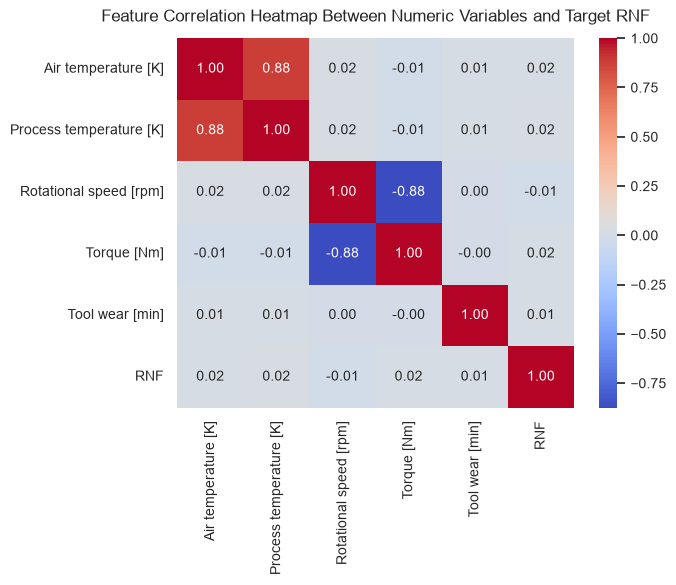

In [7]:
# plot heatmap to understand the feature correlation heatmap between numeric variables and target

title = "Feature Correlation Heatmap Between Numeric Variables and Target"
for t in target:
    plot_heatmap(df= df, num_cols= num_cols,target=t, title= f"{title} {t}")

To further investigate the relationship between Air temperature, Process temperature, Rotational speed, Torque, Tool wear and our target variables - five process failure modes, I choose boxplot to compare median and spread of each feature against with target variables.

According to the boxplots, machine with air temperature ranging from **299K** to **301K**, Process temperature ranging from **309K** to **311K** ,Rotational speed ranging from 1450rpm to 1600rpm, Torque ranging from 32Nm to 48Nm and Tool wear ranging from 50min to 151min with repect to all failure modes tend to be less failure.

Obviously, higer Rotational speed ranging from 1300rpm to 1900rpm likely to be fail due to process parameter **PWF**. Similarly, Torque ranging from 11Nm to 69Nm tend to be fail because of PWF.

There are very small range in feature Tool wear with respect to process TWF, Rotational speed with respect to process HDF and OSF.

But some feature like **Process temperature** with respect to process parameter TWF, PWF and OSF show a similar spread across both failure and proper operation of machine.

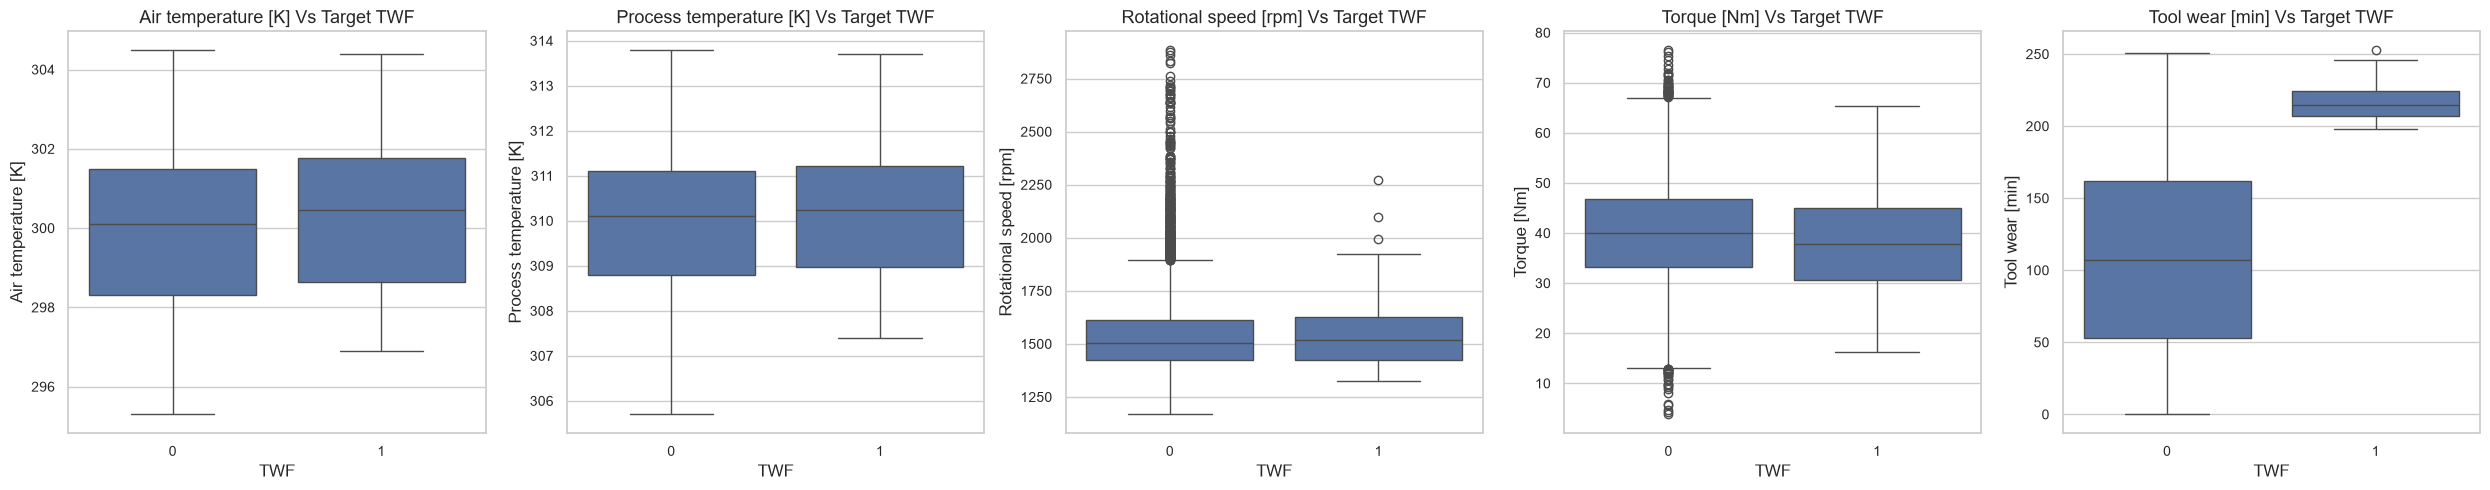

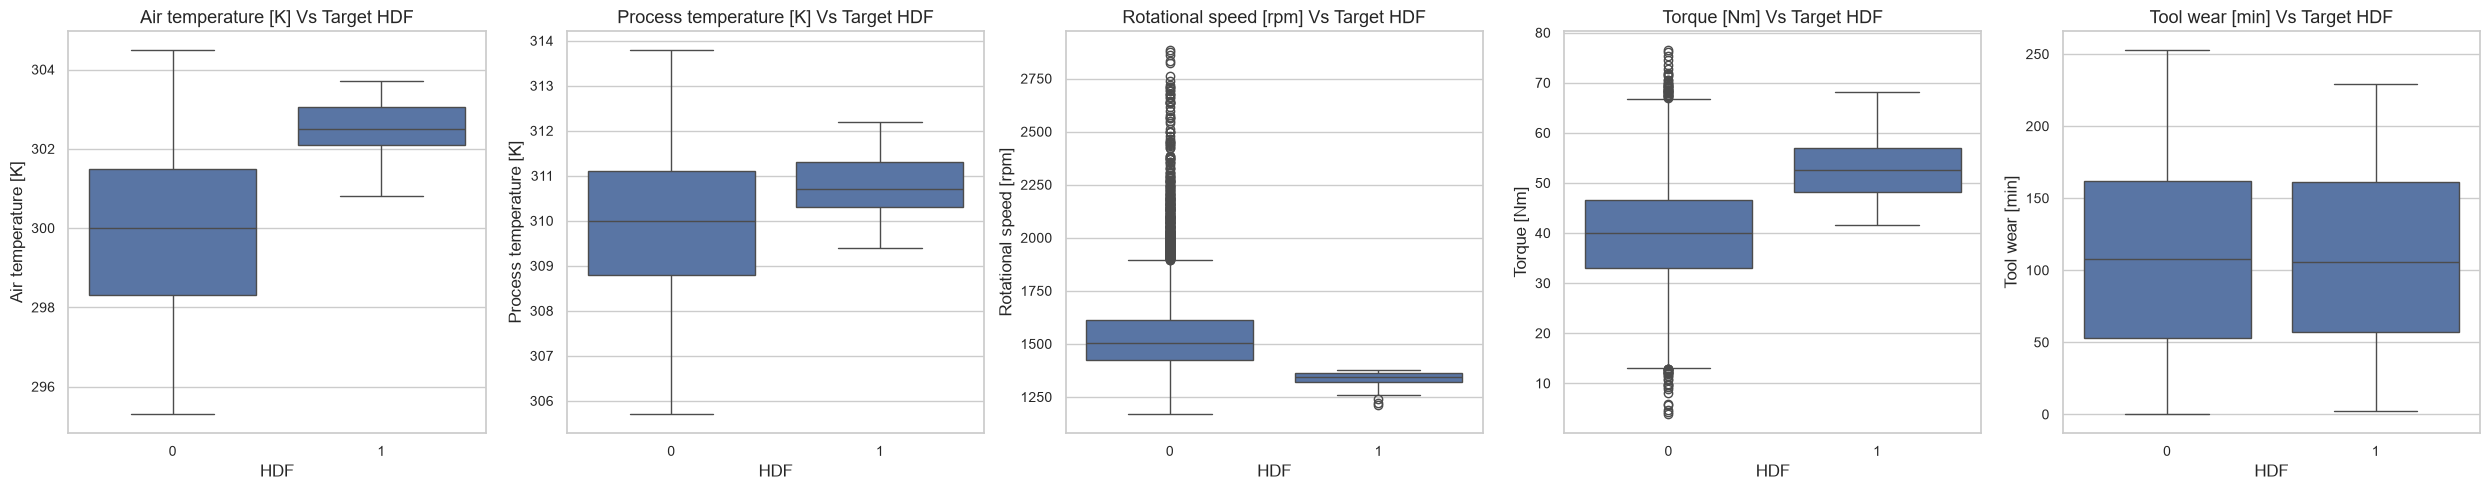

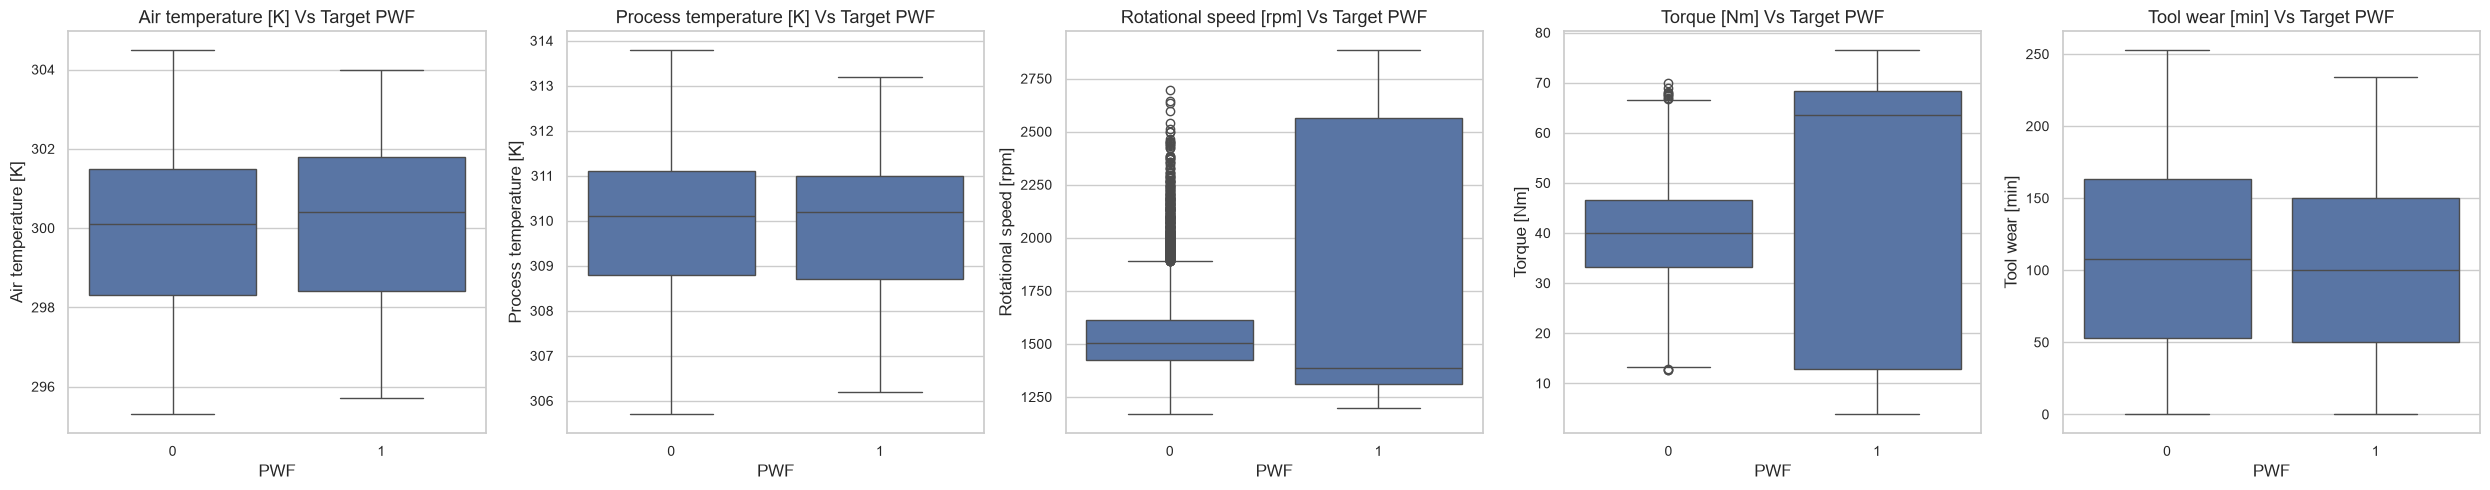

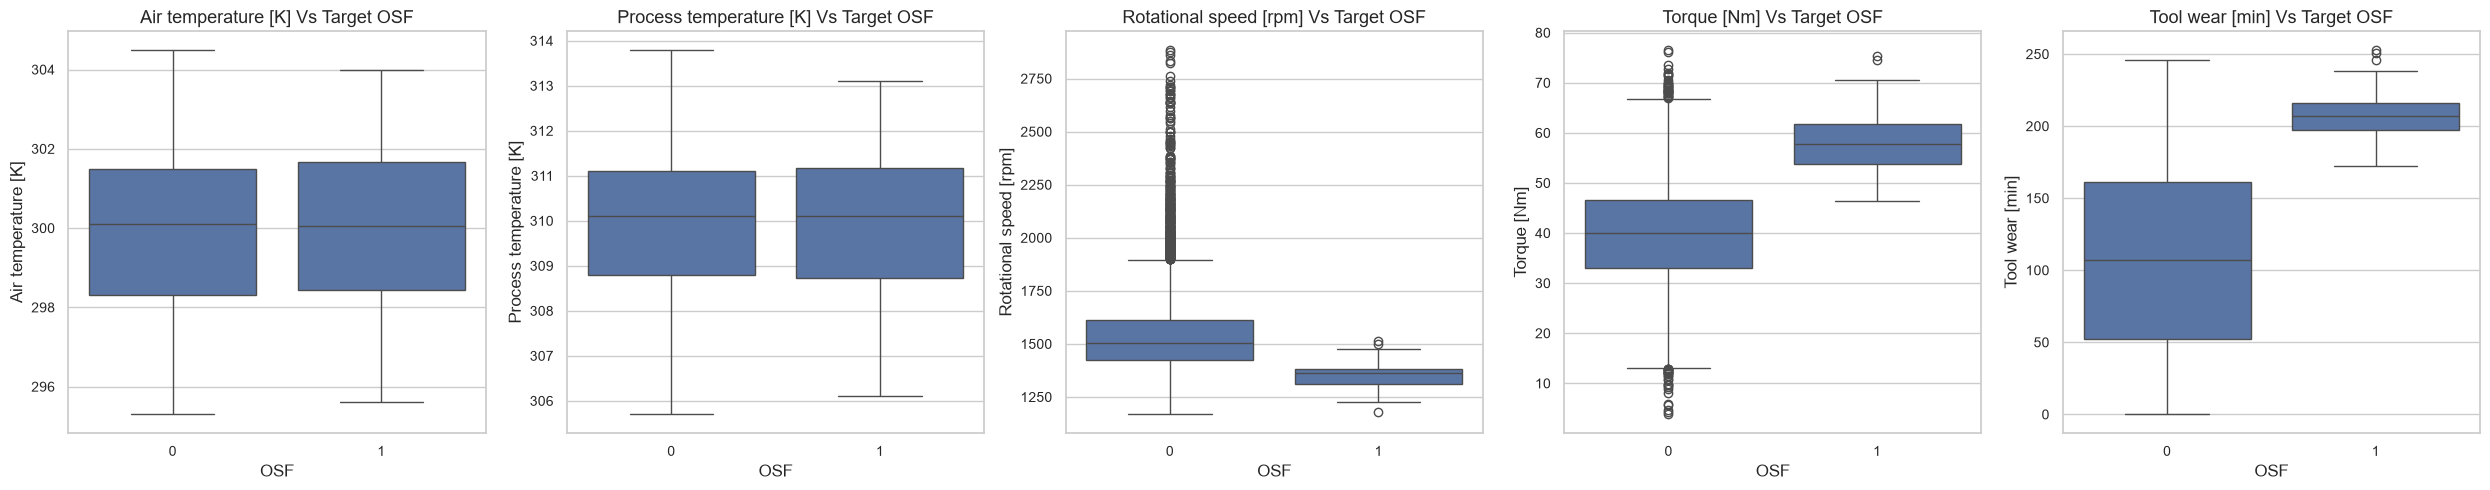

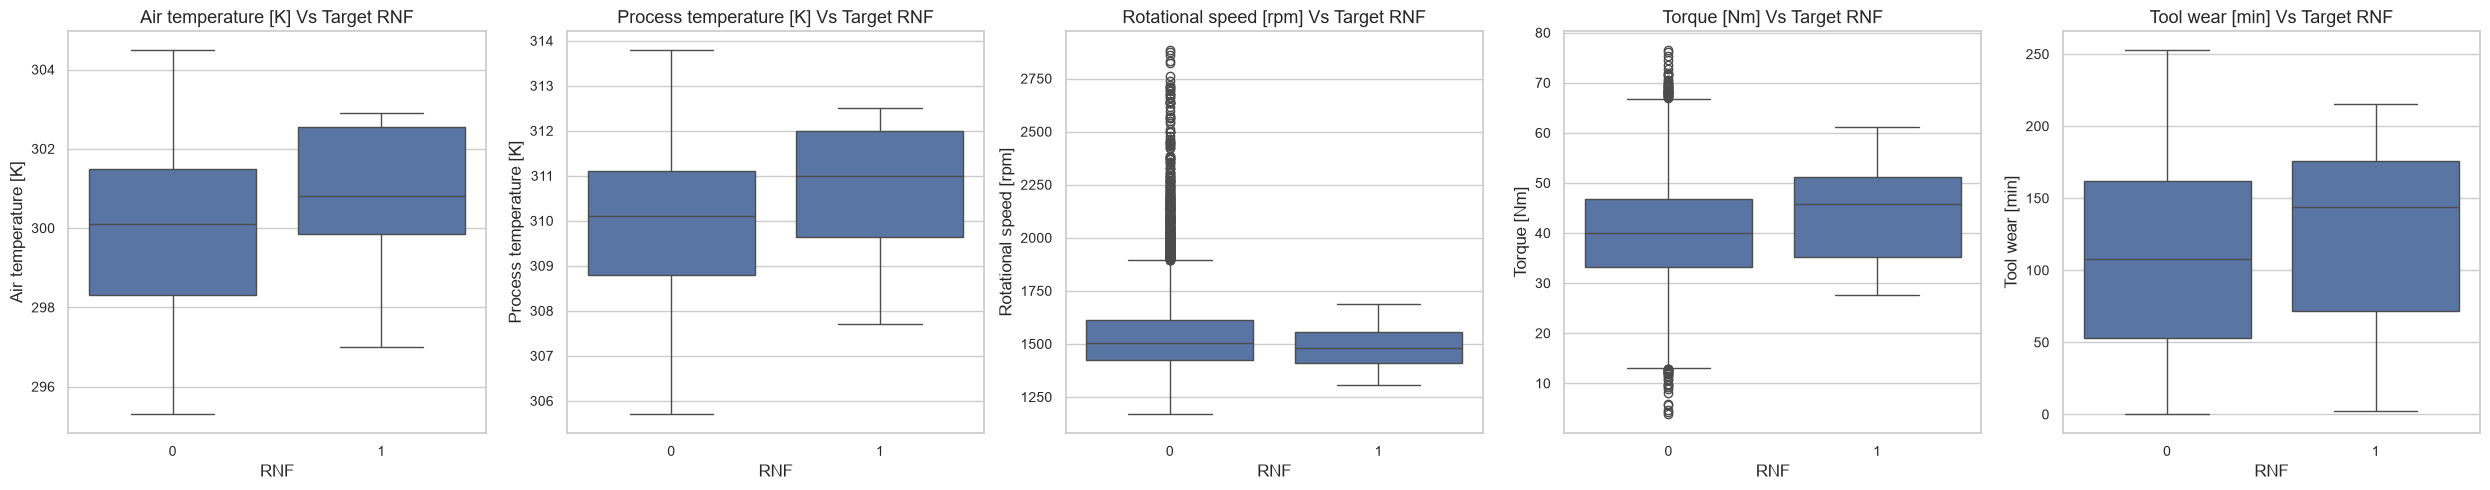

In [8]:
# plot box to understand the spread of all features against with target
   
plot_multi_box(df= df, num_cols= num_cols, target=target)

## 3.3 Categorical variables Vs Target
As we can observe in the bar plot below, machine in type L are more likely to operate properly than others machine type but as this is imbalanced data set, machine type feature could lead us misleading accuracy and incorrect analysis.

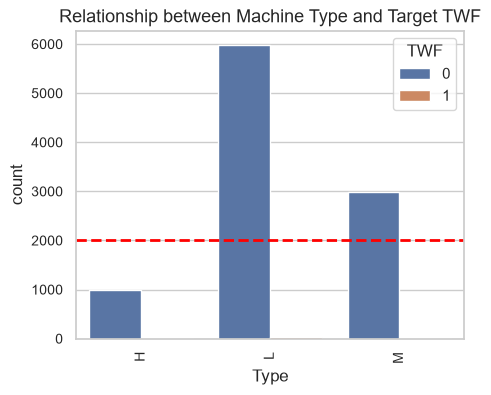

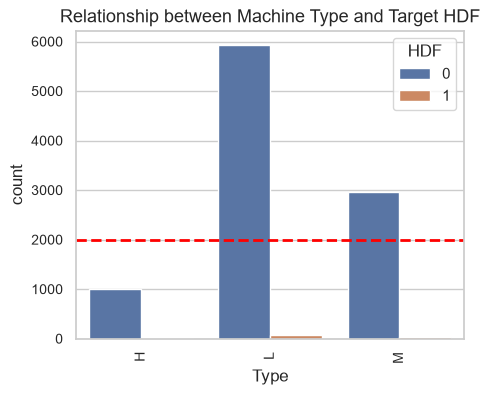

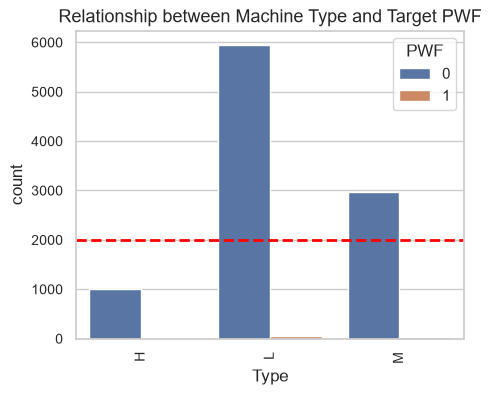

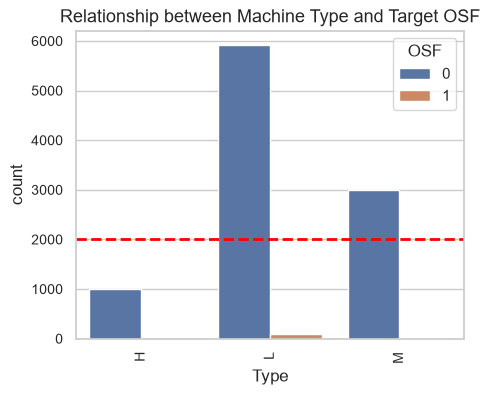

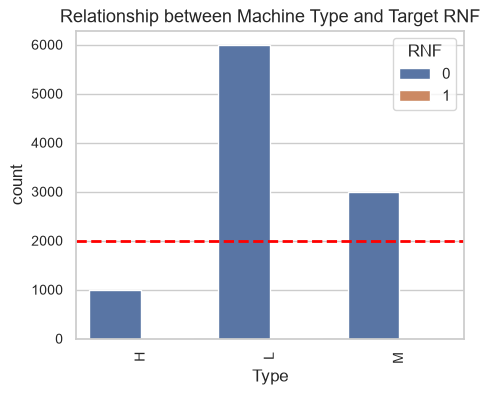

In [9]:
title = 'Relationship between Machine Type and Target'

for t in target:
    plot_bar_with_thredshold(df= df, cat_col_name= cat_cols[0], target=t,title=f"{title} {t}")



# 4. Model Fitting and Evaluation
As the dataset exhibits class imbalance, accuracy may provide a misleading assessment of model performance. Therefore, PR-AUC (Precision-Recall Area Under the Curve) is considered a more appropriate evaluation metric, as it provides a better indication of the model's ability to identify the minority class compared with individual metrics such as Precision, Recall, and F1-Score.

## 4.1 Data Preparation for Modelling
To enable modelling, I choose variables - `Type`, `Air temperature [K]`, `Process temperature [K]`,`Rotational speed [rpm]`, `Torque [Nm]`, `Tool wear [min]` as features and `TWF`, `HDF`, `PWF`, `OSF` and `RNF` as target variableS.

As the target class is highly imbalanced, with a ratio of 0.99, I decided to maintain the class distribution in both the training and test datasets by using the **stratify** argument.

In [10]:
df_class_ratio

,variable,class_ratio
0,TWF,0.9954
1,HDF,0.9885
2,PWF,0.9905
3,OSF,0.9902
4,RNF,0.9981


We need to perform proper encoding for this multi-class classification task.

If the machine does not fail, we assign the label 0. If the machine fails due to any of the following process parameters, we assign the corresponding labels:

- 1 for TWF
- 2 for HDF
- 3 for PWF
- 4 for OSF
- 5 for RNF

In [11]:
# encode target column for multi-class
overlap_records, new_target_col, df_update = encode_multiclass_target(df= df, target= target)

df = df_update

#  If a machine has two simultaneous failure modes (e.g., both TWF=1 and HDF=1) which is actually multi-label classification task
print(f"Numbers of records overlap in failures: {overlap_records}")
print(f"New target colum name after encoding: {new_target_col}")
print(f"Encoded target column : {df[new_target_col].unique()}")


Numbers of records overlap in failures: 24
New target colum name after encoding: MultiClass
Encoded target column : <ArrowStringArray>
['0', '3', '1', '4', '5', '2']
Length: 6, dtype: str


In [12]:
# dataset after encoding multi-class target
print(df.info())
df.head(3)

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  str    
 2   Type                     10000 non-null  str    
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   MultiClass               10000 non-null  str    
dtypes: float64(3), int64(4), str(3)
memory usage: 859.5 KB
None


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,MultiClass
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0


## 4.2 Select Features

In [13]:
num_feature = num_cols
cat_feature = cat_cols
print(f"numeric features : {num_feature}")
print(f"categorical features : {cat_feature}")

numeric features : ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']
categorical features : ['Type']


## 4.3 Split data to define test set

In [14]:
# split data
splitted_data = split_data(df= df,
                    target= new_target_col,
                    test_size=0.2,
                    cat_cols= cat_cols,
                    num_cols= num_cols)

list(splitted_data.keys())

['X_train', 'X_test', 'y_train', 'y_test']

In [15]:
# save splitted data
save_splitted_test_data(X_train= splitted_data['X_train'],
                        X_test= splitted_data['X_test'],
                        y_train= splitted_data['y_train'],
                        y_test=splitted_data['y_test'],
                        modeling_mode='multi')

Test dataset is successfully saved.


# 5. Model Training
- Base Model : XGBoost
- Compare Model : Light GBM
- Compare Model 2 : RandomForest Classifier

## 5.1 Base Model - XGBoost
First, we try XGBoost Classifier as base model.

In [16]:
# Convert y_train and y_test to integer type
# XGBoost expects as integers for multi-class classification

# get XGBoost model
mdl_pipeline_xgb  = get_multiclass_model(
            model_name= 'XGBClassifier',
            num_feature= num_feature,
            cat_feature= cat_feature,
            X_train= splitted_data['X_train'],
            y_train= splitted_data['y_train'].astype(int))

mdl_pipeline_xgb

{'model': 'XGBoost',
 'pipeline': Pipeline(steps=[('preprocess',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['Air temperature [K]',
                                                    'Process temperature [K]',
                                                    'Rotational speed [rpm]',
                                                    'Torque [Nm]',
                                                    'Tool wear [min]']),
                                                  ('cat',
                                                   OneHotEncoder(handle_unknown='ignore'),
                                                   ['Type'])])),
                 ('classifier',
                  XGBClassifier(base_score=None, booster=None, callbacks=None,
                                colsample_bylevel=None, colsample_b...
                                feature_types=None, feature_weights=None,
                 

## 5.2 Compare Model 1 - LightGBM

In [17]:
# get lightGBM model
mdl_pipeline_lgb  = get_multiclass_model(
            model_name= 'LGBMClassifier',
            num_feature= num_feature,
            cat_feature= cat_feature,
            X_train= splitted_data['X_train'],
            y_train= splitted_data['y_train'].astype(int))

mdl_pipeline_lgb

{'model': 'LightGBM',
 'pipeline': Pipeline(steps=[('preprocess',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['Air temperature [K]',
                                                    'Process temperature [K]',
                                                    'Rotational speed [rpm]',
                                                    'Torque [Nm]',
                                                    'Tool wear [min]']),
                                                  ('cat',
                                                   OneHotEncoder(handle_unknown='ignore',
                                                                 sparse_output=False),
                                                   ['Type'])])),
                 ('classifier',
                  LGBMClassifier(colsample_bytree=0.8, max_depth=7, num_class=6,
                                 objective='multiclass', random_state=42,

## 5.3 Compare Model 2 - random forest classifier

In [19]:
# get random forest model
mdl_pipeline_rdf  = get_multiclass_model(
            model_name= 'RandomForestClassifier',
            num_feature= num_feature,
            cat_feature= cat_feature,
            X_train= splitted_data['X_train'],
            y_train= splitted_data['y_train'].astype(int))

mdl_pipeline_rdf

{'model': 'RandomForestClassifier',
 'pipeline': Pipeline(steps=[('preprocess',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['Air temperature [K]',
                                                    'Process temperature [K]',
                                                    'Rotational speed [rpm]',
                                                    'Torque [Nm]',
                                                    'Tool wear [min]']),
                                                  ('cat',
                                                   OneHotEncoder(handle_unknown='ignore',
                                                                 sparse_output=False),
                                                   ['Type'])])),
                 ('classifier',
                  RandomForestClassifier(class_weight='balanced', max_depth=7,
                                         n_estimators=200, n_

# 6. Model Prediction and Scoring

## 6.1 XGBoost model prediction and scoring

In [20]:
# XGBoost model prediction and scoring
pred_result_xgb = run_multiclass_prediction(model= mdl_pipeline_xgb['pipeline'], 
                                            X_test=splitted_data['X_test'])

pr_auc_xgb = get_multiclass_model_score(model= mdl_pipeline_xgb['pipeline'],
                                        y_test=splitted_data['y_test'].astype(int), 
                                        y_prob=pred_result_xgb['y_prob'])

print(f"PR_AUC: {pr_auc_xgb}")


PR_AUC: 0.645


## 6.2 Light GBM model prediction and scoring

In [21]:
# Light GBM model prediction and scoring
pred_result_lgb = run_multiclass_prediction(model= mdl_pipeline_lgb['pipeline'], 
                                            X_test=splitted_data['X_test'])

pr_auc_lgb = get_multiclass_model_score(model= mdl_pipeline_lgb['pipeline'],
                                        y_test=splitted_data['y_test'].astype(int), 
                                        y_prob=pred_result_lgb['y_prob'])

print(f"PR_AUC: {pr_auc_lgb}")

PR_AUC: 0.639


## 6.3 Random forest model prediction and scoring

In [22]:
# Random forest model prediction and scoring
pred_result_rdf = run_multiclass_prediction(model= mdl_pipeline_rdf['pipeline'], 
                                            X_test=splitted_data['X_test'])

pr_auc_rdf = get_multiclass_model_score(model= mdl_pipeline_rdf['pipeline'],
                                        y_test=splitted_data['y_test'].astype(int), 
                                        y_prob=pred_result_rdf['y_prob'])

print(f"PR_AUC: {pr_auc_rdf}")

PR_AUC: 0.559


# 7. Score Comparison

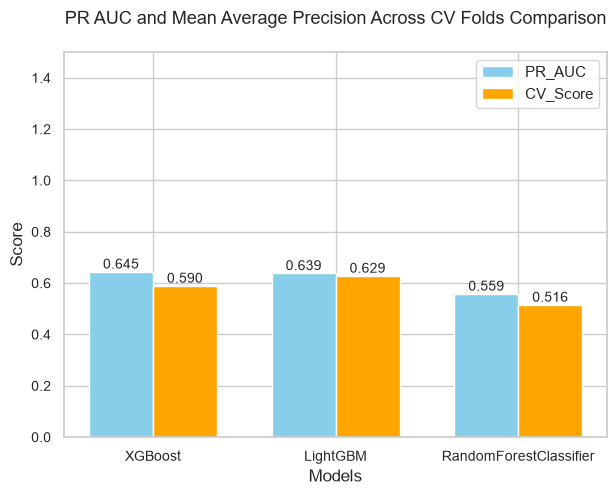

In [23]:
model_list = [ mdl_pipeline_xgb['model'], mdl_pipeline_lgb['model'], mdl_pipeline_rdf['model']]
pr_auc_list = [pr_auc_xgb, pr_auc_lgb, pr_auc_rdf]
cv_score_list = [mdl_pipeline_xgb['best_score'], mdl_pipeline_lgb['best_score'], mdl_pipeline_rdf['best_score']]

plot_score_comparison_chart(model_list=model_list,pr_auc_list=pr_auc_list, cv_score_list= cv_score_list)

In [24]:

txt_markdown = f"""
Based on the comparison, the two best-performing models are **XGBoost** and **LightGBM**.

- **XGBoost** achieves the highest performance, with a PR-AUC of `{pr_auc_xgb:.4f}` and a CV score of `{mdl_pipeline_xgb['best_score']:.4f}`, indicating strong predictive performance and consistency across cross-validation folds.
- **LightGBM** ranks second, with a PR-AUC of `{pr_auc_lgb:.4f}` and a CV score of `{mdl_pipeline_lgb['best_score']:.4f}`.
"""


display(Markdown(txt_markdown))


Based on the comparison, the two best-performing models are **XGBoost** and **LightGBM**.

- **XGBoost** achieves the highest performance, with a PR-AUC of `0.6450` and a CV score of `0.5900`, indicating strong predictive performance and consistency across cross-validation folds.
- **LightGBM** ranks second, with a PR-AUC of `0.6390` and a CV score of `0.6290`.


# 8. Finding the Feature Importance of Finalist Models
I extract features names from the preprocessing steps to get feature importance.

## 8.1 Feature Importance in XGBoost Classifier

                   feature  Importance
3              Torque [Nm]    0.253244
4          Tool wear [min]    0.172406
2   Rotational speed [rpm]    0.159932
0      Air temperature [K]    0.134017
1  Process temperature [K]    0.099157
6                   Type_L    0.082783
5                   Type_H    0.051606
7                   Type_M    0.046855


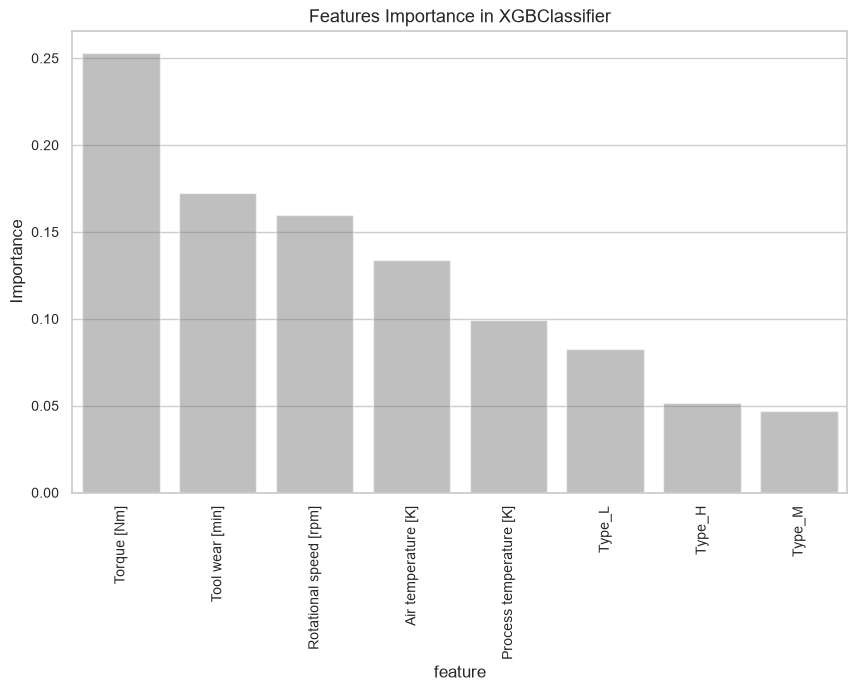

In [25]:
feature_importances_xgb  = get_feature_importance(pipeline = mdl_pipeline_xgb['pipeline'],
                                                  modeling_mode='multi')

## 8.2 Feature Importance in LightGBM

                   feature  Importance
3              Torque [Nm]        4015
2   Rotational speed [rpm]        3310
0      Air temperature [K]        3032
4          Tool wear [min]        3016
1  Process temperature [K]        2754
6                   Type_L         272
7                   Type_M         196
5                   Type_H         130


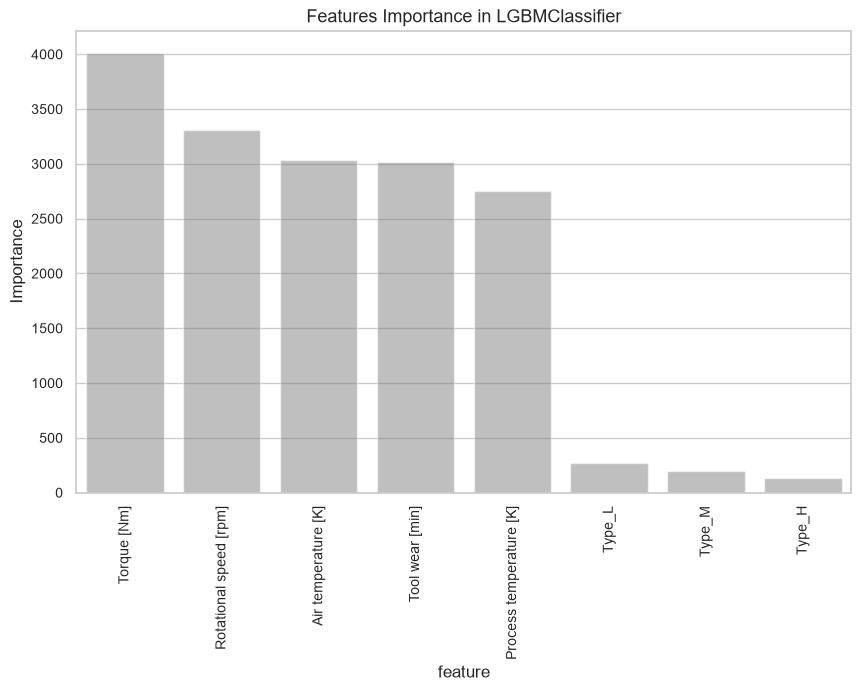

In [26]:
feature_importances_lgb = get_feature_importance(pipeline = mdl_pipeline_lgb['pipeline'],
                                                 modeling_mode='multi')

## 8.3 Importance Features

In [27]:
top_feature_xgb = pd.DataFrame(
    {'Model': mdl_pipeline_xgb['model'], 
     'Feature':feature_importances_xgb.iloc[:3]['feature'] }
    )

top_feature_lgb = pd.DataFrame(
    {'Model': mdl_pipeline_lgb['model'], 
     'Feature':feature_importances_lgb.iloc[:3]['feature'] }
     )

all_imp_features = pd.concat([top_feature_xgb, top_feature_lgb])

print(all_imp_features.to_markdown())

|    | Model    | Feature                |
|---:|:---------|:-----------------------|
|  3 | XGBoost  | Torque [Nm]            |
|  4 | XGBoost  | Tool wear [min]        |
|  2 | XGBoost  | Rotational speed [rpm] |
|  3 | LightGBM | Torque [Nm]            |
|  2 | LightGBM | Rotational speed [rpm] |
|  0 | LightGBM | Air temperature [K]    |


# 9. Save All Finalist

In [28]:
# save model for SLA evaluation
seleted_model_pipelines = [mdl_pipeline_xgb, mdl_pipeline_lgb]

save_selected_models(model_pipelines= seleted_model_pipelines,
                     modeling_mode='multi')

Models successfully saved.


## 9.1 Save Predicted Values from Finalist Models

In [29]:
# save predicted value of finalist model
selected_model_result = [{'model_name': mdl_pipeline_xgb['model'] , 'y_prob' : pred_result_xgb['y_prob']}, 
                         {'model_name' : mdl_pipeline_lgb['model'], 'y_prob': pred_result_lgb['y_prob']}
                         ]

save_predicted_prob_value(lst_model_result = selected_model_result,
                          modeling_mode= 'multi')

Predicted value successfully saved.
